# Temporal Community Detection in Stock Market Networks

This notebook studies how the community structure of the **NASDAQ-100** changes over time.
A *community* is a group of stocks whose prices tend to move together.

**Pipeline**
1. **Data:** read the index members and their sectors from Wikipedia, and download daily prices from Yahoo Finance.
2. **Rolling correlations:** split the daily returns into short time windows and compute a correlation matrix for each one.
3. **Networks:** turn each correlation matrix into a sparse network, with one node per stock and edges between strongly correlated stocks.
4. **Communities:** detect communities in every window with six methods.
5. **Comparison:** compare the methods over time on modularity, stability, agreement, conductance and within-community correlation.

**How to use:** change the values in the *Settings* cell, then run every cell from top to bottom.

In [1]:
import math
from collections import defaultdict
from itertools import combinations

import numpy as np
import pandas as pd
import yfinance as yf
import networkx as nx
import matplotlib.pyplot as plt
import community as community_louvain  # package "python-louvain"
import igraph as ig
import leidenalg as la
from sklearn.cluster import SpectralClustering

## Settings
Every option of the analysis is set here.

| Setting | Meaning |
|---|---|
| `WIKIPEDIA_URL` | Page with the constituents table. The default is a fixed revision of the *Nasdaq-100* article from 21 Dec 2022, because the current article no longer has the table. Using the members at the **start** of the period also avoids look-ahead bias. |
| `WINDOW_SIZE`, `STEP_SIZE` | Length of each window and how far it moves each time (pandas time strings such as `"14D"` or `"30D"`). |
| `MIN_PERIODS` | A window with fewer trading days than this is skipped. |
| `GRAPH_TYPE` | `"w"`: weighted, positive correlations only. `"n"`: the same edges, unweighted. `"sw"`: signed and weighted, with positive and negative correlations. |
| `MODELS` | Community detection methods to run (see section 3). |
| `N_COMMUNITIES` | Number of clusters for spectral clustering (the other methods choose this themselves). |
| `TEMPORAL_SMOOTHING` | How strongly `louvain_temporal` prefers to keep the previous window's communities (0 = no preference). |
| `SEED` | Random seed, so every run gives the same result. |

In [2]:
NAME = "NASDAQ-100"
WIKIPEDIA_URL = "https://en.wikipedia.org/w/index.php?title=Nasdaq-100&oldid=1128627537"
START_DATE = "2023-01-01"
END_DATE = "2025-01-01"
MAX_TICKERS = None          # e.g. 30 for a quick test run

WINDOW_SIZE = "14D"
STEP_SIZE = "14D"
MIN_PERIODS = 5

GRAPH_TYPE = "w"

MODELS = ("louvain", "louvain_signed", "leiden", "spectral", "louvain_temporal", "leiden_temporal")
N_COMMUNITIES = 3
TEMPORAL_SMOOTHING = 0.5
SEED = 42

# Method pairs compared with each other in the "agreement" plots
CROSS_PAIRS = [("louvain", "leiden"), ("louvain", "spectral"), ("leiden", "spectral"),
               ("louvain_signed", "louvain_temporal"), ("leiden", "leiden_temporal")]

## 1. Data
* `load_constituents` reads the first Wikipedia table that has a *Symbol* or *Ticker* column, plus its sector column if there is one.
* `load_prices` downloads daily closing prices (adjusted for splits and dividends). Stocks with missing days in the period are dropped, for example a company that left the index and was delisted.
* `rolling_correlations` cuts the daily returns into windows and computes the Pearson correlation matrix of each window.

In [3]:
SECTOR_COLUMNS = ("gics sector", "sector", "industry", "gics sectors", "icb industry", "sub-industry")


def yahoo_ticker(symbol):
    """Wikipedia writes share classes with a dot (BRK.B); Yahoo Finance uses a dash (BRK-B)."""
    return str(symbol).replace(".", "-")


def load_constituents(url, max_tickers=None):
    """Read index members from a Wikipedia page.

    Returns
    -------
    symbols : list of Yahoo Finance tickers
    sectors : dict ticker -> sector name ("Unknown" if the table has no sector column)
    """
    tables = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
    for table in tables:
        columns = {str(c).lower(): c for c in table.columns}
        symbol_col = columns.get("symbol") or columns.get("ticker")
        if symbol_col is None:
            continue
        sector_col = next((columns[c] for c in SECTOR_COLUMNS if c in columns), None)
        symbols = [yahoo_ticker(s) for s in table[symbol_col]]
        if max_tickers:
            symbols = symbols[:max_tickers]
        if sector_col is None:
            sectors = {s: "Unknown" for s in symbols}
        else:
            sectors = {yahoo_ticker(s): str(sec) for s, sec in zip(table[symbol_col], table[sector_col])}
        return symbols, sectors
    raise ValueError(f"No table with a 'Symbol' or 'Ticker' column was found at {url}. "
                     "If the article changed, point WIKIPEDIA_URL to an older revision (…/w/index.php?title=…&oldid=…).")


def load_prices(symbols, start_date, end_date):
    """Daily closing prices, one column per ticker. Tickers with any missing day are dropped."""
    prices = yf.download(symbols, start=start_date, end=end_date, auto_adjust=True, progress=False)["Close"]
    complete = prices.dropna(axis=1)
    dropped = [s for s in prices.columns if s not in complete.columns]
    if dropped:
        print(f"Dropped {len(dropped)} tickers with missing prices: {', '.join(dropped)}")
    return complete


def rolling_correlations(returns, window_size, step_size, min_periods):
    """Correlation matrix of each window [start, start + window_size), moving by step_size.

    Returns (windows, matrices, n_days): the (start, end) dates, the correlation
    matrices and the number of trading days in each window.
    """
    window, step = pd.Timedelta(window_size), pd.Timedelta(step_size)
    windows, matrices, n_days = [], [], []
    start, last_day = returns.index.min(), returns.index.max()
    while start + window <= last_day:
        chunk = returns.loc[(returns.index >= start) & (returns.index < start + window)]
        if len(chunk) >= min_periods:
            windows.append((start, start + window))
            matrices.append(chunk.corr())
            n_days.append(len(chunk))
        start += step
    return windows, matrices, n_days

## 2. From correlations to networks
A full correlation matrix links every pair of stocks, so it is too dense to show structure. `build_pd_graph` keeps a fixed number of edges, `3n − 6` by default, which is the edge count of a planar maximally filtered graph:

1. **Similarity.** For `"w"` and `"n"` the similarity is the correlation, with negative values set to 0. For `"sw"` it is the absolute correlation.
2. **Degree budget.** Each stock gets a target degree proportional to its total similarity, rounded to whole numbers so that the degrees add up to exactly twice the edge budget (`cascade_rounding`).
3. **Edges.** Pairs are added from most to least similar, as long as both stocks still have free degree.

Edge weights are the correlation for `"w"` and `"sw"` (so `"sw"` can contain negative edges), and 1 for `"n"`.

In [4]:
GRAPH_TYPES = {
    "w": "weighted, positive correlations only",
    "n": "unweighted, positive correlations only",
    "sw": "signed and weighted, positive and negative correlations",
}


def cascade_rounding(targets):
    """Round non-negative real targets to integers while keeping their total (cumulative rounding)."""
    rounded_cumulative = np.rint(np.cumsum(targets))
    degrees = np.zeros(len(targets), dtype=int)
    previous = 0
    for i, value in enumerate(rounded_cumulative):
        degrees[i] = int(value - previous)
        previous = value
    return degrees


def build_pd_graph(corr, graph_type="w", sectors=None, n_edges=None):
    """Sparse network from a correlation matrix (DataFrame) with a fixed edge budget."""
    if graph_type not in GRAPH_TYPES:
        raise ValueError(f"graph_type must be one of {list(GRAPH_TYPES)}, got {graph_type!r}")
    labels = list(corr.columns)
    values = corr.values
    n = len(labels)
    if n_edges is None:
        n_edges = 3 * n - 6

    # 1. similarity matrix (no self-similarity; undefined correlations count as 0)
    similarity = abs(values) if graph_type == "sw" else np.maximum(values, 0)
    similarity[similarity != similarity] = 0          # NaN is the only value not equal to itself
    for i in range(n):
        similarity[i, i] = 0

    # 2. degree budget proportional to each stock's total similarity
    strength = np.sum(similarity, axis=1)
    total = strength.sum()
    targets = strength / total * (2 * n_edges) if total > 0 else np.zeros(n)
    order = np.argsort(-strength)
    max_degree = np.zeros(n, dtype=int)
    max_degree[order] = cascade_rounding(targets[order])

    # 3. greedy edge selection, most similar pairs first
    pairs = sorted(((similarity[i, j], i, j) for i in range(n) for j in range(i + 1, n)),
                   key=lambda pair: -pair[0])
    G = nx.Graph()
    G.add_nodes_from(labels)
    degree = np.zeros(n, dtype=int)
    for sim, i, j in pairs:
        if sim <= 0 or G.number_of_edges() >= n_edges:
            break
        if degree[i] < max_degree[i] and degree[j] < max_degree[j]:
            weight = 1.0 if graph_type == "n" else float(values[i, j])
            G.add_edge(labels[i], labels[j], weight=weight)
            degree[i] += 1
            degree[j] += 1

    for node in G.nodes:
        G.nodes[node]["sector"] = (sectors or {}).get(node, "Unknown")
    return G


def positive_part(G):
    """Copy of G without its negative edges (needed by methods that only accept non-negative weights)."""
    H = nx.Graph()
    H.add_nodes_from(G.nodes)
    for u, v, data in G.edges(data=True):
        if data["weight"] > 0:
            H.add_edge(u, v, weight=data["weight"])
    return H


def analyze_graph(G):
    """Basic statistics of a network: size, density, connectivity and edge weights."""
    weights = [data["weight"] for _, _, data in G.edges(data=True)]
    n, m = G.number_of_nodes(), G.number_of_edges()
    return {
        "nodes": n,
        "edges": m,
        "density": nx.density(G),
        "avg_degree": 2 * m / n if n else 0,
        "isolated_nodes": sum(1 for node in G.nodes if len(G[node]) == 0),
        "largest_component": max(len(c) for c in nx.connected_components(G)) if n else 0,
        "negative_edges": sum(1 for w in weights if w < 0),
        "min_weight": min(weights) if weights else None,
        "max_weight": max(weights) if weights else None,
        "mean_weight": sum(weights) / len(weights) if weights else None,
    }

## 3. Community detection

| Method | What it does |
|---|---|
| `louvain` | Louvain modularity optimisation (`python-louvain`) on the positive edges. |
| `louvain_signed` | Our own Louvain implementation for **signed** networks. It rewards positive edges inside communities and negative edges between them. |
| `leiden` | Leiden algorithm (`leidenalg`) on the positive edges. It is an improved Louvain that guarantees well-connected communities. |
| `spectral` | Spectral clustering of the window's positive correlations into `N_COMMUNITIES` groups. It uses the full correlation matrix, because the sparse network is often disconnected. |
| `louvain_temporal` | `louvain_signed` plus a bonus for keeping together stocks that were together in the previous window, which gives smoother community evolution. |
| `leiden_temporal` | Leiden started from the previous window's communities instead of from scratch. |

The *temporal* methods use the result of the previous window, so the windows are processed in time order.

**How `signed_louvain` works.** It maximises `Q = Q⁺ − Q⁻ (+ smoothing · T)`, where:
* `Q⁺` and `Q⁻` are the modularity of the positive and the negative edges, each measured against its own total weight;
* `T` is the modularity of the current partition measured on the **previous window's communities**, viewed as a network that links every pair of stocks that shared a community. It rewards keeping those pairs together, and like any modularity it penalises merging communities that were separate.

It repeats two phases until no stock moves:
1. **Local moving:** each node moves to the neighbouring community with the largest gain in `Q`.
2. **Aggregation:** each community is merged into one *super-node*. Weights inside a community are kept as self-loops, so the totals don't change.

In [5]:
def louvain(G, seed=42):
    """Louvain (python-louvain) on the positive edges of G. Returns {node: community}."""
    return community_louvain.best_partition(positive_part(G), weight="weight", random_state=seed)


def leiden(G, initial_partition=None, seed=42):
    """Leiden (leidenalg, modularity) on the positive edges of G.

    initial_partition: optional {node: community} to start from (used by leiden_temporal).
    """
    H = positive_part(G)
    nodes = list(H.nodes())
    index = {node: i for i, node in enumerate(nodes)}
    graph = ig.Graph(len(nodes))
    graph.vs["name"] = nodes
    graph.add_edges([(index[u], index[v]) for u, v in H.edges()])
    graph.es["weight"] = [H[u][v]["weight"] for u, v in H.edges()]

    initial = None
    if initial_partition is not None:
        # leidenalg wants community numbers 0, 1, 2, ...; stocks without a previous community start alone
        numbering = {}
        keys = [initial_partition.get(node, ("new", node)) for node in nodes]
        initial = [numbering.setdefault(key, len(numbering)) for key in keys]

    result = la.find_partition(graph, la.ModularityVertexPartition, weights="weight",
                               initial_membership=initial, seed=seed)
    return dict(zip(nodes, result.membership))


def spectral(corr, n_communities=3, seed=42):
    """Spectral clustering of a correlation matrix (DataFrame) into n_communities groups.

    The affinity is the positive part of the correlations. It uses the full matrix rather than
    the sparse graph, because the sparse graph is often disconnected and spectral clustering
    works poorly on disconnected graphs.
    """
    affinity = np.maximum(corr.values, 0)
    affinity[affinity != affinity] = 0            # undefined correlations count as 0
    labels = SpectralClustering(n_clusters=n_communities, affinity="precomputed",
                                assign_labels="discretize", random_state=seed).fit_predict(affinity)
    return {node: int(label) for node, label in zip(corr.columns, labels)}


def signed_louvain(G, previous_partition=None, smoothing=0.0, tol=1e-12):
    """Louvain method for signed weighted networks, optionally smoothed over time (see the text above).

    previous_partition : {node: community} of the previous window, or None
    smoothing          : weight of the temporal term T (0 = plain signed Louvain)
    Returns {node: community}.
    """
    # Signed adjacency, positive and negative magnitudes kept apart: {node: {neighbour: weight}}
    pos = {u: defaultdict(float) for u in G.nodes()}
    neg = {u: defaultdict(float) for u in G.nodes()}
    for u, v, data in G.edges(data=True):
        w = data.get("weight", 1.0)
        side = pos if w >= 0 else neg
        side[u][v] += abs(w)
        side[v][u] += abs(w)
    m_pos = sum(sum(nbrs.values()) for nbrs in pos.values()) / 2
    m_neg = sum(sum(nbrs.values()) for nbrs in neg.values()) / 2

    # Temporal term: each (super-)node counts how many of its stocks were in each previous community
    history = {u: defaultdict(int) for u in G.nodes()}
    if previous_partition is not None and smoothing > 0:
        for u in G.nodes():
            if u in previous_partition:
                history[u][previous_partition[u]] += 1
    previous_sizes = defaultdict(int)
    for counts in history.values():
        for label, count in counts.items():
            previous_sizes[label] += count
    # The previous partition seen as a network that links every pair of stocks that shared a community:
    # it has history_pairs edges, and a stock in a previous community of size s has degree s - 1.
    history_pairs = sum(s * (s - 1) / 2 for s in previous_sizes.values())
    use_history = history_pairs > 0

    def modularity_gain(link, k, total, m):
        """Gain of adding a node with strength k and weight `link` towards a community of total strength `total`."""
        return link / m - k * total / (2 * m * m) if m > 0 else 0.0

    members = {u: [u] for u in G.nodes()}   # super-node -> original stocks
    while True:
        nodes = list(pos)
        community = {u: u for u in nodes}
        k_pos = {u: sum(pos[u].values()) for u in nodes}
        k_neg = {u: sum(neg[u].values()) for u in nodes}
        tot_pos, tot_neg = dict(k_pos), dict(k_neg)
        tot_history = {u: defaultdict(int, history[u]) for u in nodes}
        k_hist = {u: sum(count * (previous_sizes[label] - 1) for label, count in history[u].items()) for u in nodes}
        tot_hist = dict(k_hist)

        # Phase 1: local moving
        moved, improved = False, True
        while improved:
            improved = False
            for u in nodes:
                old = community[u]
                tot_pos[old] -= k_pos[u]
                tot_neg[old] -= k_neg[u]
                tot_hist[old] -= k_hist[u]
                for label, count in history[u].items():
                    tot_history[old][label] -= count

                link_pos, link_neg = defaultdict(float), defaultdict(float)
                for v, w in pos[u].items():
                    if v != u:
                        link_pos[community[v]] += w
                for v, w in neg[u].items():
                    if v != u:
                        link_neg[community[v]] += w

                def gain(c):
                    g = (modularity_gain(link_pos[c], k_pos[u], tot_pos[c], m_pos)
                         - modularity_gain(link_neg[c], k_neg[u], tot_neg[c], m_neg))
                    if use_history:
                        # stock pairs (u, member of c) that shared a community in the previous window
                        link_hist = sum(count * tot_history[c][label] for label, count in history[u].items())
                        g += smoothing * modularity_gain(link_hist, k_hist[u], tot_hist[c], history_pairs)
                    return g

                best, best_gain = old, gain(old)
                for c in list(link_pos) + list(link_neg):
                    g = gain(c)
                    if g > best_gain + tol:
                        best, best_gain = c, g

                community[u] = best
                tot_pos[best] += k_pos[u]
                tot_neg[best] += k_neg[u]
                tot_hist[best] += k_hist[u]
                for label, count in history[u].items():
                    tot_history[best][label] += count
                if best != old:
                    improved = moved = True

        if not moved:
            break

        # Phase 2: aggregation (communities become super-nodes; internal weight becomes a self-loop)
        new_members = defaultdict(list)
        for u in nodes:
            new_members[community[u]].extend(members[u])
        new_pos = {c: defaultdict(float) for c in new_members}
        new_neg = {c: defaultdict(float) for c in new_members}
        new_history = {c: defaultdict(int) for c in new_members}
        for u in nodes:
            cu = community[u]
            for v, w in pos[u].items():
                new_pos[cu][community[v]] += w
            for v, w in neg[u].items():
                new_neg[cu][community[v]] += w
            for label, count in history[u].items():
                new_history[cu][label] += count
        pos, neg, history, members = new_pos, new_neg, new_history, dict(new_members)

    return {stock: index for index, group in enumerate(members.values()) for stock in group}


MODEL_DESCRIPTIONS = {
    "louvain": "Louvain on positive edges",
    "louvain_signed": "signed Louvain",
    "leiden": "Leiden on positive edges",
    "spectral": "spectral clustering",
    "louvain_temporal": "signed Louvain + temporal smoothing",
    "leiden_temporal": "Leiden warm-started from the previous window",
}


def detect_communities(G, method, corr, previous_partition=None, n_communities=3, smoothing=0.5, seed=42):
    """Run one community detection method on network G (built from correlation matrix corr).
    Returns {node: community}."""
    if method == "louvain":
        return louvain(G, seed)
    if method == "louvain_signed":
        return signed_louvain(G)
    if method == "leiden":
        return leiden(G, seed=seed)
    if method == "spectral":
        return spectral(corr, n_communities, seed)
    if method == "louvain_temporal":
        return signed_louvain(G, previous_partition, smoothing)
    if method == "leiden_temporal":
        return leiden(G, previous_partition, seed)
    raise ValueError(f"Unknown method {method!r}. Choose from: {', '.join(MODEL_DESCRIPTIONS)}")

## 4. Evaluation metrics

| Metric | Meaning | Better |
|---|---|---|
| **Modularity** | How much more weight lies inside communities than expected at random. Computed on the positive edges, so all methods are measured the same way. | higher |
| **VI** (variation of information) | Information-theoretic distance between two partitions: `H₁ + H₂ − 2I`. 0 means identical. | lower = more similar |
| **NMI** (normalised mutual information) | `2I / (H₁ + H₂)`: 1 means identical, 0 means unrelated. | higher = more similar |
| **Conductance** | Share of a community's edge weight that leaves it, `cut / (cut + inside)`, using absolute weights. | lower |
| **Within-community correlation** | Mean Pearson correlation over all pairs of stocks in a community, taken from the window's full correlation matrix. | higher |

VI and NMI between **consecutive windows** measure how *stable* a method is over time. Between **two methods in the same window** they measure how much the methods *agree*.

In [6]:
def group_by_community(partition):
    """{community: [nodes]} from {node: community}."""
    groups = defaultdict(list)
    for node, com in partition.items():
        groups[com].append(node)
    return dict(groups)


def community_sizes(partition):
    """{community: number of nodes}, largest first."""
    sizes = {com: len(nodes) for com, nodes in group_by_community(partition).items()}
    return dict(sorted(sizes.items(), key=lambda item: -item[1]))


def modularity(G, partition):
    """Modularity of a partition on the positive edges of G (NaN if there are none)."""
    H = positive_part(G)
    if H.number_of_edges() == 0:
        return np.nan
    return community_louvain.modularity(partition, H, weight="weight")


def entropies_and_mutual_information(part1, part2):
    """Entropy of each partition and their mutual information (natural log), over the shared nodes."""
    nodes = [node for node in part1 if node in part2]
    N = len(nodes)
    if N == 0:
        return 0.0, 0.0, 0.0
    count1, count2, joint = defaultdict(int), defaultdict(int), defaultdict(int)
    for node in nodes:
        count1[part1[node]] += 1
        count2[part2[node]] += 1
        joint[(part1[node], part2[node])] += 1
    H1 = -sum(c / N * math.log(c / N) for c in count1.values())
    H2 = -sum(c / N * math.log(c / N) for c in count2.values())
    I = sum(c / N * math.log(c * N / (count1[a] * count2[b])) for (a, b), c in joint.items())
    return H1, H2, I


def variation_of_information(part1, part2):
    """VI = H1 + H2 - 2I (0 = identical partitions)."""
    H1, H2, I = entropies_and_mutual_information(part1, part2)
    return max(0.0, H1 + H2 - 2 * I)


def normalized_mutual_information(part1, part2):
    """NMI = 2I / (H1 + H2) (1 = identical; also 1 when both partitions are a single community)."""
    H1, H2, I = entropies_and_mutual_information(part1, part2)
    return 2 * I / (H1 + H2) if H1 + H2 > 0 else 1.0


def conductance(G, partition):
    """{community: conductance}, using |weight|. Communities without any edges are left out."""
    result = {}
    for com, nodes in group_by_community(partition).items():
        node_set = set(nodes)
        inside = leaving = 0.0
        for u in nodes:
            for v, data in G[u].items():
                w = abs(data.get("weight", 1.0))
                if v in node_set:
                    inside += w / 2        # every internal edge is seen from both of its ends
                else:
                    leaving += w
        if inside + leaving > 0:
            result[com] = leaving / (inside + leaving)
    return result


def average_within_correlation(corr, partition):
    """{community: mean correlation over all its stock pairs}. Single-stock communities are left out."""
    position = {name: i for i, name in enumerate(corr.columns)}
    values = corr.values
    result = {}
    for com, nodes in group_by_community(partition).items():
        pairs = list(combinations(nodes, 2))
        if pairs:
            result[com] = sum(values[position[u], position[v]] for u, v in pairs) / len(pairs)
    return result


def mean(values):
    """Average of a list (NaN for an empty list)."""
    values = list(values)
    return sum(values) / len(values) if values else np.nan

## 5. Plotting helpers

In [7]:
def draw_network(G, groups, title, k=0.4):
    """Draw G with a spring layout. groups: {node: group name}; each group gets its own colour.

    Red edges are negative, grey edges positive; edge width grows with |weight|.
    """
    names = sorted(set(groups.values()), key=str)
    colour = {name: f"C{i % 10}" for i, name in enumerate(names)}   # 10 distinct colours, then repeats
    edges = G.edges(data=True)
    pos = nx.spring_layout(G, k=k, iterations=50, seed=42)

    plt.figure(figsize=(14, 14))
    nx.draw_networkx_nodes(G, pos, node_color=[colour[groups[n]] for n in G.nodes()], node_size=120)
    nx.draw_networkx_edges(G, pos, edge_color=["red" if d["weight"] < 0 else "grey" for _, _, d in edges],
                           width=[abs(d["weight"]) * 3 for _, _, d in edges], alpha=0.5)
    nx.draw_networkx_labels(G, pos, font_size=6)
    for name in names:                                  # legend entries
        plt.plot([], [], "o", color=colour[name], label=str(name))
    plt.legend(loc="upper left")
    plt.title(title)
    plt.axis("off")
    plt.show()


def plot_over_time(tables, column, title, ylabel):
    """Line plot of tables[label][column] against the window end date, one line per label."""
    plt.figure(figsize=(12, 5))
    for label, table in tables.items():
        plt.plot(table["window_end"], table[column], marker="o", label=label)
    plt.title(title)
    plt.xlabel("Window end date")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 6. The `MarketAnalyzer` class
This class runs the analysis for one index and keeps every intermediate result as an attribute: prices, windows, graphs and partitions.

* **Data:** `load_data()` runs `load_metadata()`, `load_prices()` and `compute_correlations()`.
* **Temporal analysis:** `main_temporal_pipeline(...)` runs `compute_temporal_correlations()`, `build_temporal_graphs()` and `detect_temporal_communities()`.
* **Full-period snapshot:** `build_graph()` and `detect_static_communities()`.
* **Results:** the `compute_*` methods return `{method: DataFrame}` tables, one row per window. `plot_metric(name)` plots any of them; the names are listed in `MarketAnalyzer.PLOTS`.
* **Inspection:** `print_community_summary()`, `plot_network_by_sector()` and `plot_network_by_partition()`. Pass `window=None` for the full period, or a window number (`-1` = last).

In [8]:
class MarketAnalyzer:
    # plot name -> (table method, column, axis label)
    PLOTS = {
        "modularity": ("compute_community_summary", "modularity", "Modularity"),
        "num_communities": ("compute_community_summary", "num_communities", "Number of communities"),
        "vi_prev": ("compute_vi_nmi_self_vs_prev", "VI_prev", "VI vs previous window"),
        "nmi_prev": ("compute_vi_nmi_self_vs_prev", "NMI_prev", "NMI vs previous window"),
        "vi_cross": ("compute_vi_nmi_cross_models", "VI", "VI between methods"),
        "nmi_cross": ("compute_vi_nmi_cross_models", "NMI", "NMI between methods"),
        "conductance": ("compute_conductance_over_time", "conductance_mean", "Mean conductance"),
        "avg_corr": ("compute_avg_corr_over_time", "avg_corr_mean", "Mean within-community correlation"),
    }

    def __init__(self, wikipedia_url, start_date="2023-01-01", end_date="2025-01-01",
                 max_tickers=None, name="Market"):
        self.wikipedia_url = wikipedia_url
        self.start_date, self.end_date = start_date, end_date
        self.max_tickers = max_tickers
        self.name = name
        # data
        self.symbols = self.sectors = self.prices = self.returns = self.corr_matrix = None
        # full-period snapshot
        self.G = None
        self.static_partitions = {}
        # temporal analysis
        self.graph_type = None
        self.models = ()
        self.windows, self.temporal_corr_matrices, self.temporal_graphs = [], [], []
        self.temporal_partitions = {}          # method -> [partition of window 0, window 1, ...]

    # ------------------------------------------------------------------ data
    def load_metadata(self):
        self.symbols, self.sectors = load_constituents(self.wikipedia_url, self.max_tickers)
        print(f"{len(self.symbols)} tickers read from Wikipedia")

    def load_prices(self):
        self.prices = load_prices(self.symbols, self.start_date, self.end_date)
        self.returns = self.prices.pct_change().dropna()
        print(f"Prices for {self.prices.shape[1]} stocks over {len(self.returns)} trading days")

    def compute_correlations(self):
        self.corr_matrix = self.returns.corr()

    def load_data(self):
        self.load_metadata()
        self.load_prices()
        self.compute_correlations()

    # ------------------------------------------------------------------ temporal pipeline
    def compute_temporal_correlations(self, window_size="14D", step_size="14D", min_periods=5):
        if self.returns is None:
            raise ValueError("No price data yet: call load_data() first.")
        self.windows, self.temporal_corr_matrices, n_days = rolling_correlations(
            self.returns, window_size, step_size, min_periods)
        if not self.windows:
            raise ValueError("No window has enough trading days; use a longer period or smaller MIN_PERIODS.")
        n_stocks = self.returns.shape[1]
        print(f"{len(self.windows)} windows of {window_size} every {step_size}, "
              f"{min(n_days)}-{max(n_days)} trading days each, {n_stocks} stocks")
        if max(n_days) < n_stocks:
            print("Note: each window has fewer trading days than stocks, so the correlations are noisy "
                  "estimates. Longer windows give more stable networks.")

    def build_temporal_graphs(self, graph_type="w"):
        self.graph_type = graph_type
        self.temporal_graphs = [build_pd_graph(corr, graph_type, self.sectors)
                                for corr in self.temporal_corr_matrices]
        print(f"Built {len(self.temporal_graphs)} {GRAPH_TYPES[graph_type]} graphs")

    def detect_temporal_communities(self, models=MODELS, n_communities=3, smoothing=0.5, seed=42):
        """Partition every window with every method. Temporal methods use their own previous result."""
        unknown = [m for m in models if m not in MODEL_DESCRIPTIONS]
        if unknown:
            raise ValueError(f"Unknown methods {unknown}. Choose from: {', '.join(MODEL_DESCRIPTIONS)}")
        self.models = tuple(models)
        self.temporal_partitions = {method: [] for method in self.models}
        for G, corr in zip(self.temporal_graphs, self.temporal_corr_matrices):
            for method in self.models:
                history = self.temporal_partitions[method]
                previous = history[-1] if history else None
                try:
                    partition = detect_communities(G, method, corr, previous, n_communities, smoothing, seed)
                except Exception as error:
                    print(f"[WARN] {method} failed on a window: {error}")
                    partition = None
                history.append(partition)
        for method in self.models:
            ok = sum(p is not None for p in self.temporal_partitions[method])
            print(f"  {method:<17} ({MODEL_DESCRIPTIONS[method]}): {ok}/{len(self.temporal_graphs)} windows")

    def main_temporal_pipeline(self, models=MODELS, window_size="14D", step_size="14D", min_periods=5,
                               graph_type="w", n_communities=3, smoothing=0.5, seed=42):
        self.compute_temporal_correlations(window_size, step_size, min_periods)
        self.build_temporal_graphs(graph_type)
        self.detect_temporal_communities(models, n_communities, smoothing, seed)

    @property
    def last_temporal_partition(self):
        """{method: partition of the last window}."""
        return {method: parts[-1] for method, parts in self.temporal_partitions.items() if parts}

    # ------------------------------------------------------------------ full-period snapshot
    def build_graph(self, graph_type="w"):
        """Network of the whole period (one correlation matrix over all days)."""
        self.G = build_pd_graph(self.corr_matrix, graph_type, self.sectors)
        return self.G

    def detect_static_communities(self, models=("louvain", "louvain_signed", "leiden", "spectral"),
                                  n_communities=3, seed=42):
        for method in models:
            self.static_partitions[method] = detect_communities(self.G, method, self.corr_matrix, None,
                                                                n_communities, 0.0, seed)
        return self.static_partitions

    # ------------------------------------------------------------------ result tables
    def _window_table(self, rows):
        """DataFrame with one row per window: t, window_start, window_end, then the given values."""
        return pd.DataFrame([{"t": t, "window_start": start, "window_end": end, **row}
                             for t, ((start, end), row) in enumerate(zip(self.windows, rows))])

    def _score_methods(self, score, methods=None):
        """{method: table}; score(method, t, partition) returns the values of window t as a dict."""
        tables = {}
        for method in methods or self.models:
            rows = [score(method, t, part) if part is not None else {}
                    for t, part in enumerate(self.temporal_partitions[method])]
            tables[method] = self._window_table(rows)
        return tables

    def summarize_temporal_diagnostics(self):
        """Structure of every window's graph (same graphs for all methods)."""
        return self._window_table([analyze_graph(G) for G in self.temporal_graphs])

    def compute_community_summary(self, methods=None):
        def score(method, t, part):
            sizes = community_sizes(part)
            return {"modularity": modularity(self.temporal_graphs[t], part),
                    "num_communities": len(sizes), "community_sizes": sizes}
        return self._score_methods(score, methods)

    def compute_vi_nmi_self_vs_prev(self, methods=None):
        def score(method, t, part):
            previous = self.temporal_partitions[method][t - 1] if t > 0 else None
            if previous is None:
                return {}
            return {"VI_prev": variation_of_information(previous, part),
                    "NMI_prev": normalized_mutual_information(previous, part)}
        return self._score_methods(score, methods)

    def compute_vi_nmi_cross_models(self, method_pairs=None):
        tables = {}
        for m1, m2 in method_pairs or list(combinations(self.models, 2)):
            rows = [{} if p1 is None or p2 is None else
                    {"VI": variation_of_information(p1, p2), "NMI": normalized_mutual_information(p1, p2)}
                    for p1, p2 in zip(self.temporal_partitions[m1], self.temporal_partitions[m2])]
            tables[f"{m1} vs {m2}"] = self._window_table(rows)
        return tables

    def compute_conductance_over_time(self, methods=None):
        def score(method, t, part):
            return {"conductance_mean": mean(conductance(self.temporal_graphs[t], part).values())}
        return self._score_methods(score, methods)

    def compute_avg_corr_over_time(self, methods=None):
        def score(method, t, part):
            values = average_within_correlation(self.temporal_corr_matrices[t], part).values()
            return {"avg_corr_mean": mean(values)}
        return self._score_methods(score, methods)

    # ------------------------------------------------------------------ plots
    def plot_metric(self, metric, methods=None, title=None):
        """Plot one metric over time. metric: a key of MarketAnalyzer.PLOTS.
        methods: list of methods (or of method pairs for "vi_cross"/"nmi_cross"); default = all."""
        if metric not in self.PLOTS:
            raise ValueError(f"Unknown metric {metric!r}. Choose from: {', '.join(self.PLOTS)}")
        table_method, column, label = self.PLOTS[metric]
        tables = getattr(self, table_method)(methods)
        plot_over_time(tables, column, title or f"{self.name}: {label} over time", label)

    def plot_structure_over_time(self, title=None):
        """Number of edges (left axis) and density (right axis) of each window's graph."""
        table = self.summarize_temporal_diagnostics()
        fig, ax1 = plt.subplots(figsize=(12, 5))
        ax1.plot(table["window_end"], table["edges"], marker="o", color="blue")
        ax1.set_ylabel("Edges", color="blue")
        ax1.tick_params(axis="y", labelcolor="blue")
        ax2 = ax1.twinx()
        ax2.plot(table["window_end"], table["density"], marker="s", color="red")
        ax2.set_ylabel("Density", color="red")
        ax2.tick_params(axis="y", labelcolor="red")
        plt.title(title or f"{self.name}: edges and density per window")
        fig.tight_layout()
        plt.show()

    # ------------------------------------------------------------------ inspection
    def _graph(self, window):
        return self.G if window is None else self.temporal_graphs[window]

    def _partition(self, method, window):
        return self.static_partitions.get(method) if window is None else self.temporal_partitions[method][window]

    def _when(self, window):
        if window is None:
            return f"{self.start_date} to {self.end_date}"
        start, end = self.windows[window]
        return f"window {start:%Y-%m-%d} to {end:%Y-%m-%d}"

    def plot_network_by_sector(self, window=None, k=0.4):
        G = self._graph(window)
        draw_network(G, {n: G.nodes[n]["sector"] for n in G.nodes}, f"{self.name} by sector ({self._when(window)})", k)

    def plot_network_by_partition(self, method, window=None, k=0.4):
        partition = self._partition(method, window)
        groups = {node: f"community {com}" for node, com in partition.items()}
        draw_network(self._graph(window), groups, f"{self.name}: {method} communities ({self._when(window)})", k)

    def print_community_summary(self, method, window=None):
        """Modularity, then size, main sector and members of each community."""
        G, partition = self._graph(window), self._partition(method, window)
        if partition is None:
            print(f"No {method} partition for {self._when(window)}.")
            return
        print(f"=== {method} communities, {self._when(window)} ===")
        print(f"modularity: {modularity(G, partition):.3f}")
        groups = group_by_community(partition)
        for com in community_sizes(partition):
            nodes = sorted(groups[com])
            sector_counts = defaultdict(int)
            for node in nodes:
                sector_counts[G.nodes[node]["sector"]] += 1
            top = max(sector_counts, key=sector_counts.get)
            print(f"  community {com}: {len(nodes)} stocks, mainly {top} ({sector_counts[top]}/{len(nodes)})")
            print(f"    {', '.join(nodes)}")

## 7. Run the analysis
This downloads the data, builds one network per window and runs every method in `MODELS` on every window.

In [9]:
market = MarketAnalyzer(WIKIPEDIA_URL, START_DATE, END_DATE, MAX_TICKERS, name=NAME)
market.load_data()
market.main_temporal_pipeline(models=MODELS, window_size=WINDOW_SIZE, step_size=STEP_SIZE,
                              min_periods=MIN_PERIODS, graph_type=GRAPH_TYPE,
                              n_communities=N_COMMUNITIES, smoothing=TEMPORAL_SMOOTHING, seed=SEED)

101 tickers read from Wikipedia


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: ANSS"}}}


HTTP Error 404: {"quoteSummary":{"result":null,"error":{"code":"Not Found","description":"Quote not found for symbol: WBA"}}}



6 Failed downloads:


['EA', 'WBD']: YFPricesMissingError('possibly delisted; no price data found  (1d 2023-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1672549200, endDate = 1735707600")')


['ANSS', 'WBA', 'ATVI', 'SGEN']: YFTzMissingError('possibly delisted; no timezone found')


Dropped 6 tickers with missing prices: ANSS, ATVI, EA, SGEN, WBA, WBD
Prices for 95 stocks over 501 trading days


51 windows of 14D every 14D, 8-10 trading days each, 95 stocks
Note: each window has fewer trading days than stocks, so the correlations are noisy estimates. Longer windows give more stable networks.


Built 51 weighted, positive correlations only graphs


  louvain           (Louvain on positive edges): 51/51 windows
  louvain_signed    (signed Louvain): 51/51 windows
  leiden            (Leiden on positive edges): 51/51 windows
  spectral          (spectral clustering): 51/51 windows
  louvain_temporal  (signed Louvain + temporal smoothing): 51/51 windows
  leiden_temporal   (Leiden warm-started from the previous window): 51/51 windows


## 8. Results over time
### Network structure
The edge budget is fixed at `3n − 6`, so the edge count only drops when stocks run out of free degree, or when there are too few positive correlations for `"w"` and `"n"`.

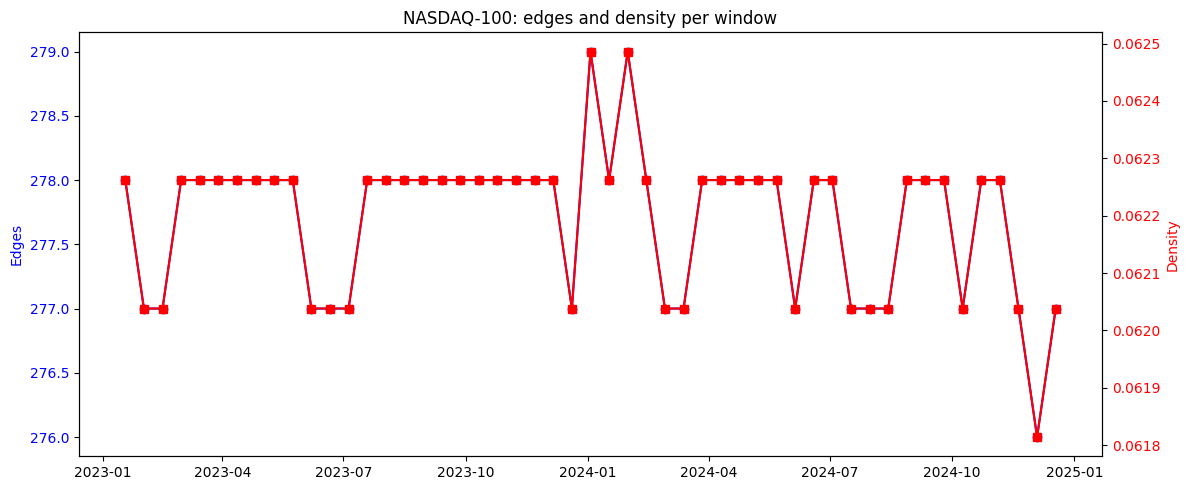

,t,window_start,window_end,nodes,edges,density,avg_degree,isolated_nodes,largest_component,negative_edges,min_weight,max_weight,mean_weight
0,0,2023-01-04,2023-01-18,95,278,0.062262,5.852632,0,95,0,0.142359,0.996606,0.816730
1,1,2023-01-18,2023-02-01,95,277,0.062038,5.831579,2,93,0,0.420308,0.997232,0.831260
2,2,2023-02-01,2023-02-15,95,277,0.062038,5.831579,1,94,0,0.053631,0.998709,0.815734
3,3,2023-02-15,2023-03-01,95,278,0.062262,5.852632,0,95,0,0.216303,0.999216,0.816655
4,4,2023-03-01,2023-03-15,95,278,0.062262,5.852632,0,95,0,0.089514,0.995965,0.816266
5,5,2023-03-15,2023-03-29,95,278,0.062262,5.852632,0,95,0,0.018916,0.998578,0.806253
6,6,2023-03-29,2023-04-12,95,278,0.062262,5.852632,0,95,0,0.265070,0.996214,0.805433
7,7,2023-04-12,2023-04-26,95,278,0.062262,5.852632,1,92,0,0.066367,0.993643,0.786878
8,8,2023-04-26,2023-05-10,95,278,0.062262,5.852632,0,95,0,0.077992,0.994597,0.755816
9,9,2023-05-10,2023-05-24,95,278,0.062262,5.852632,1,94,0,0.139134,0.997788,0.774205


In [10]:
market.plot_structure_over_time()
market.summarize_temporal_diagnostics()

### Community structure: modularity and number of communities

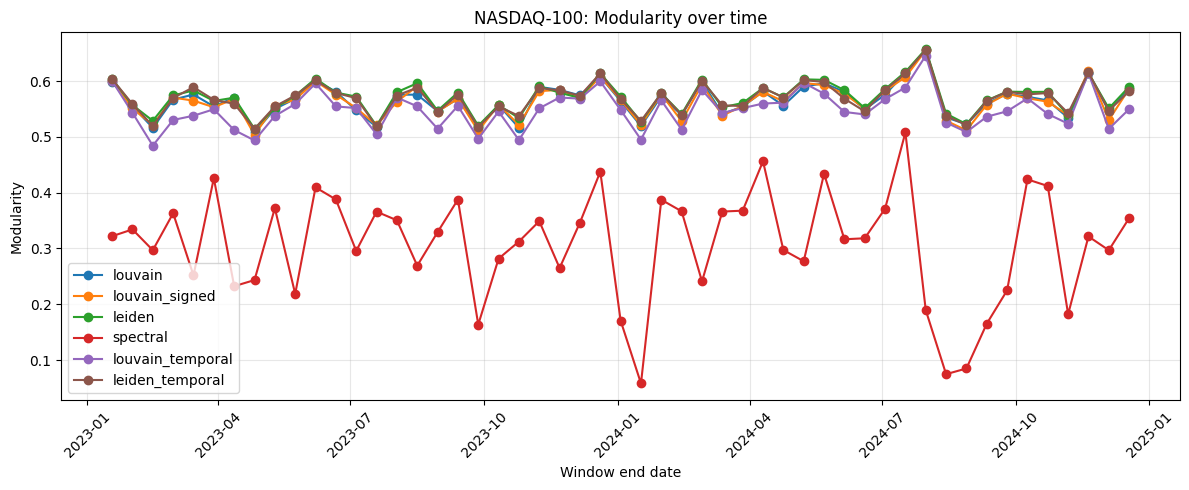

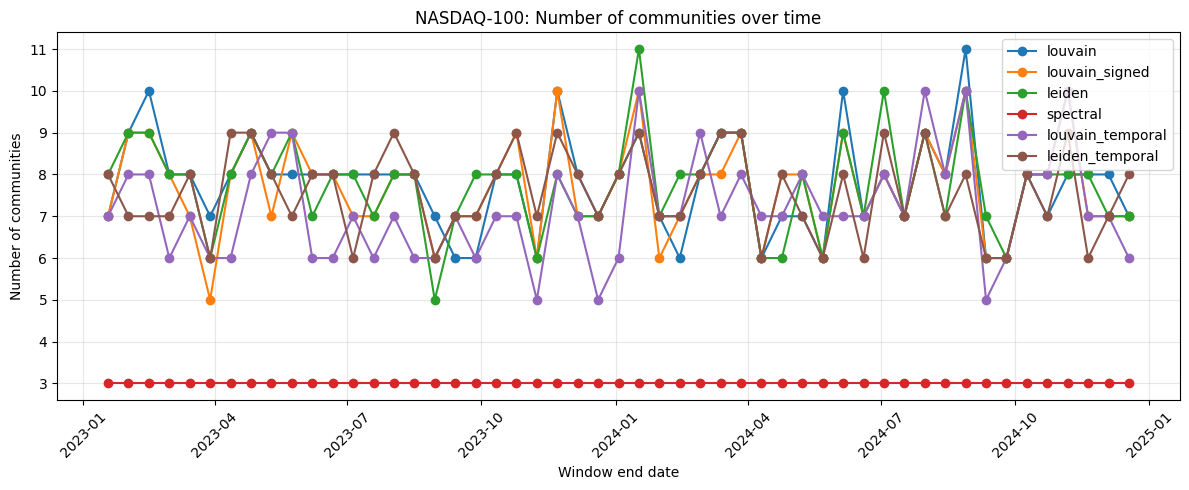

In [11]:
market.plot_metric("modularity")
market.plot_metric("num_communities")

### Stability: how much each method's communities change from one window to the next

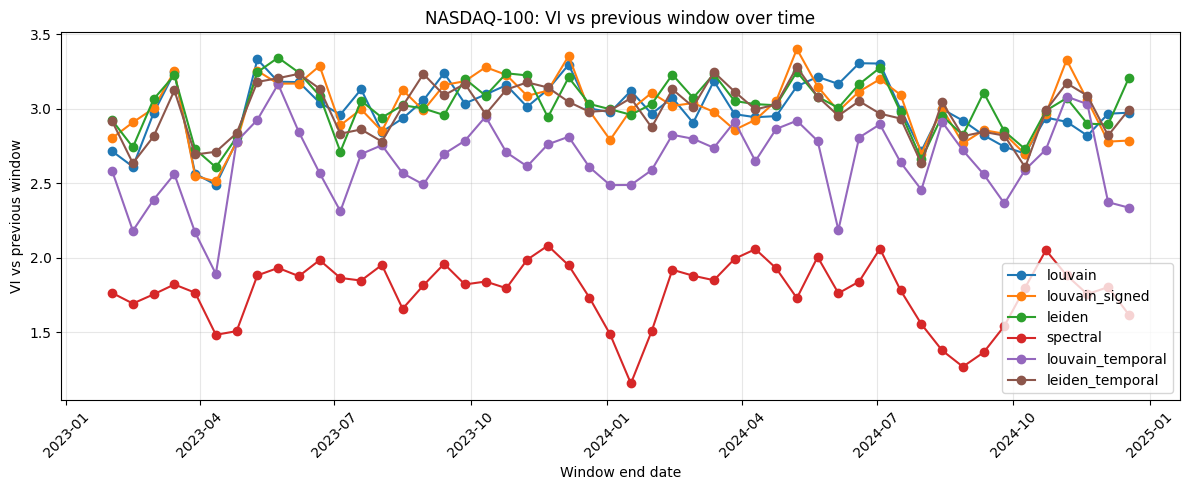

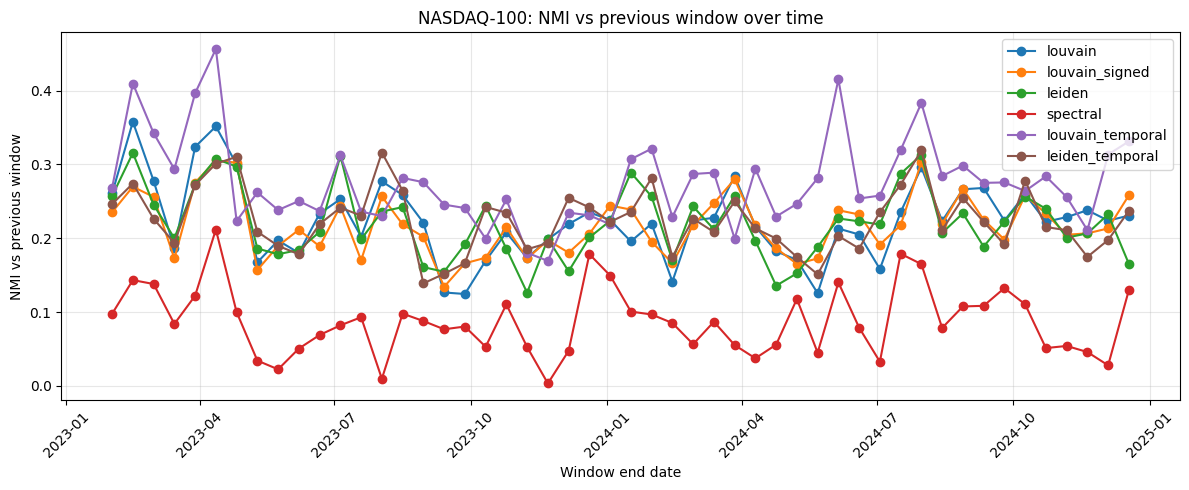

In [12]:
market.plot_metric("vi_prev")
market.plot_metric("nmi_prev")

### Agreement: how similar two methods' communities are in the same window

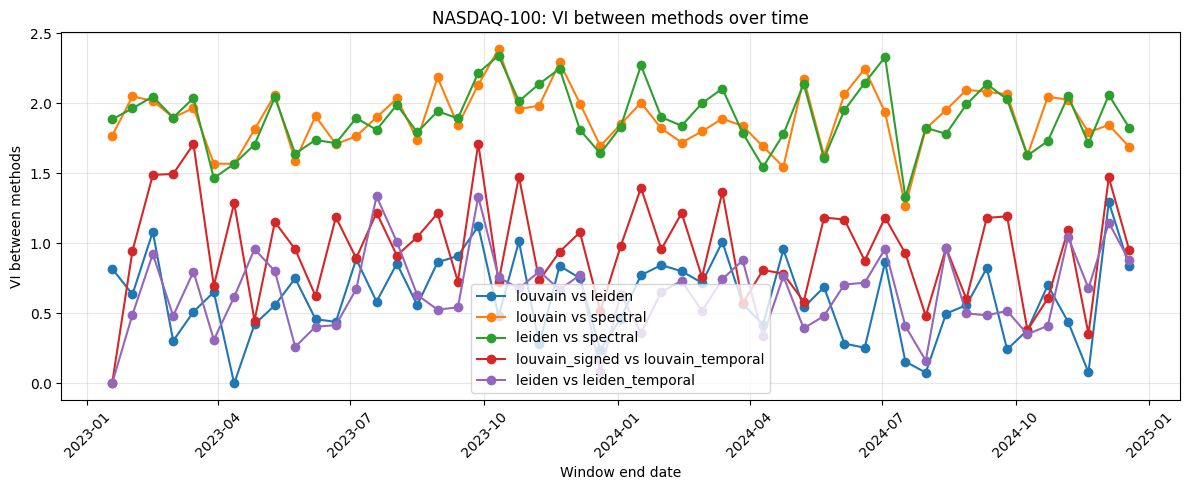

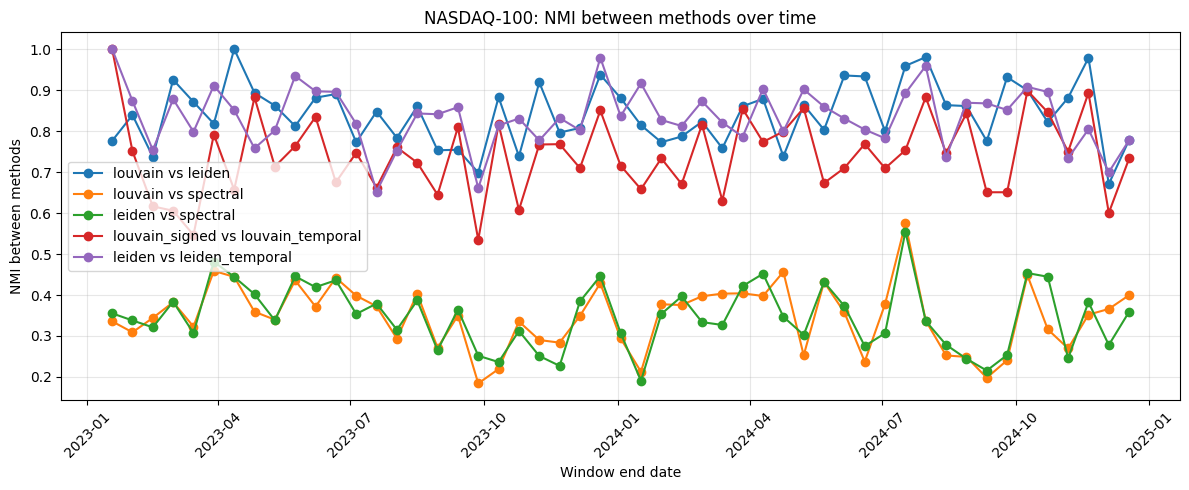

In [13]:
market.plot_metric("vi_cross", CROSS_PAIRS)
market.plot_metric("nmi_cross", CROSS_PAIRS)

### Community quality: conductance and within-community correlation

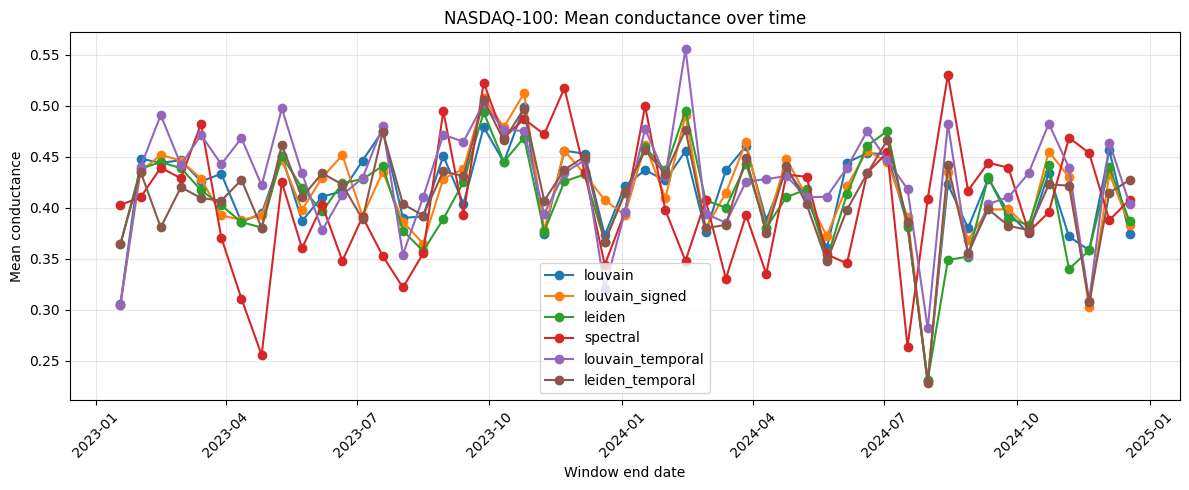

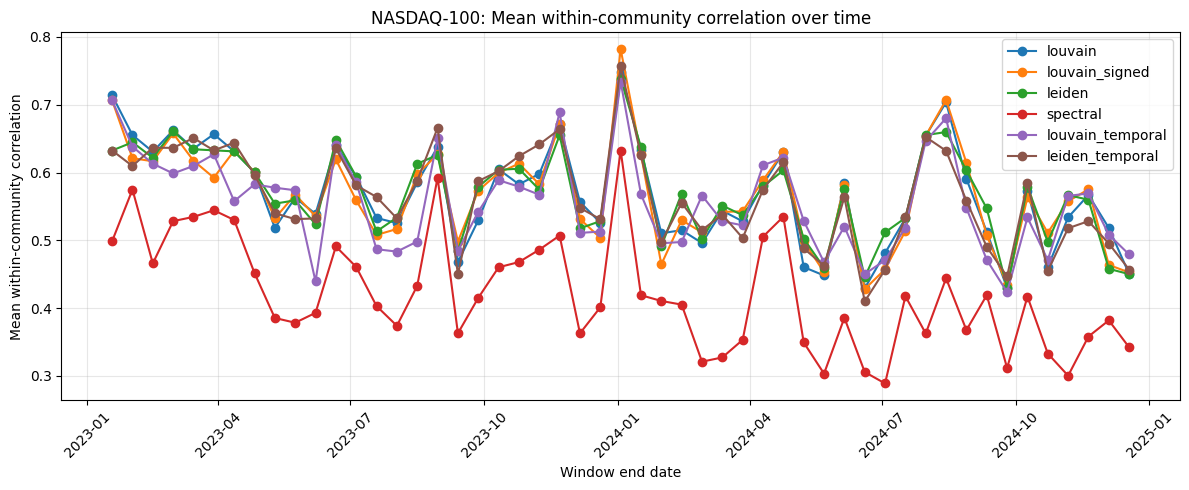

In [14]:
market.plot_metric("conductance")
market.plot_metric("avg_corr")

### Average of each metric over all windows

In [15]:
communities = market.compute_community_summary()
stability = market.compute_vi_nmi_self_vs_prev()
conductances = market.compute_conductance_over_time()
correlations = market.compute_avg_corr_over_time()
pd.DataFrame([{
    "method": method,
    "modularity": mean(communities[method]["modularity"].dropna()),
    "num_communities": mean(communities[method]["num_communities"].dropna()),
    "NMI_prev (stability)": mean(stability[method]["NMI_prev"].dropna()),
    "conductance": mean(conductances[method]["conductance_mean"].dropna()),
    "within_corr": mean(correlations[method]["avg_corr_mean"].dropna()),
} for method in market.models]).set_index("method")

,modularity,num_communities,NMI_prev (stability),conductance,within_corr
method,,,,,
louvain,0.565199,7.764706,0.224118,0.414742,0.568070
louvain_signed,0.564240,7.686275,0.217947,0.414327,0.566084
leiden,0.571127,7.764706,0.220138,0.408488,0.568905
spectral,0.307414,3.000000,0.087450,0.406659,0.421479
louvain_temporal,0.548835,7.196078,0.275852,0.428369,0.555633
leiden_temporal,0.569260,7.568627,0.224540,0.412270,0.564103


## 9. Full-period snapshot
One network built from the correlations over the **whole period**, colored by sector and by the communities found.

{'nodes': 95, 'edges': 279, 'density': 0.06248600223964166, 'avg_degree': 5.873684210526315, 'isolated_nodes': 0, 'largest_component': 95, 'negative_edges': 0, 'min_weight': 0.05925608144761698, 'max_weight': 0.9975818949997515, 'mean_weight': 0.4483477195331768}


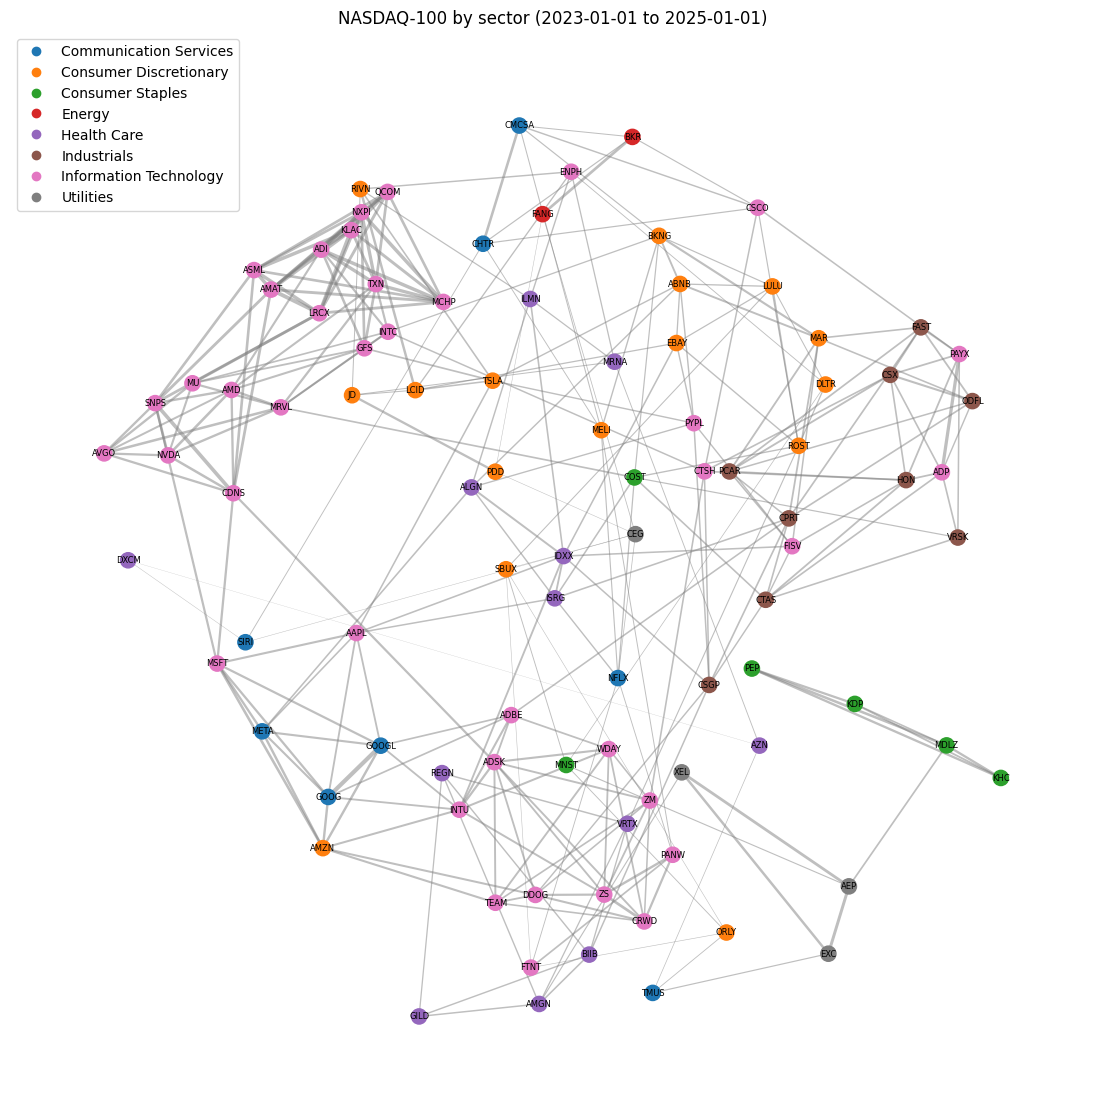

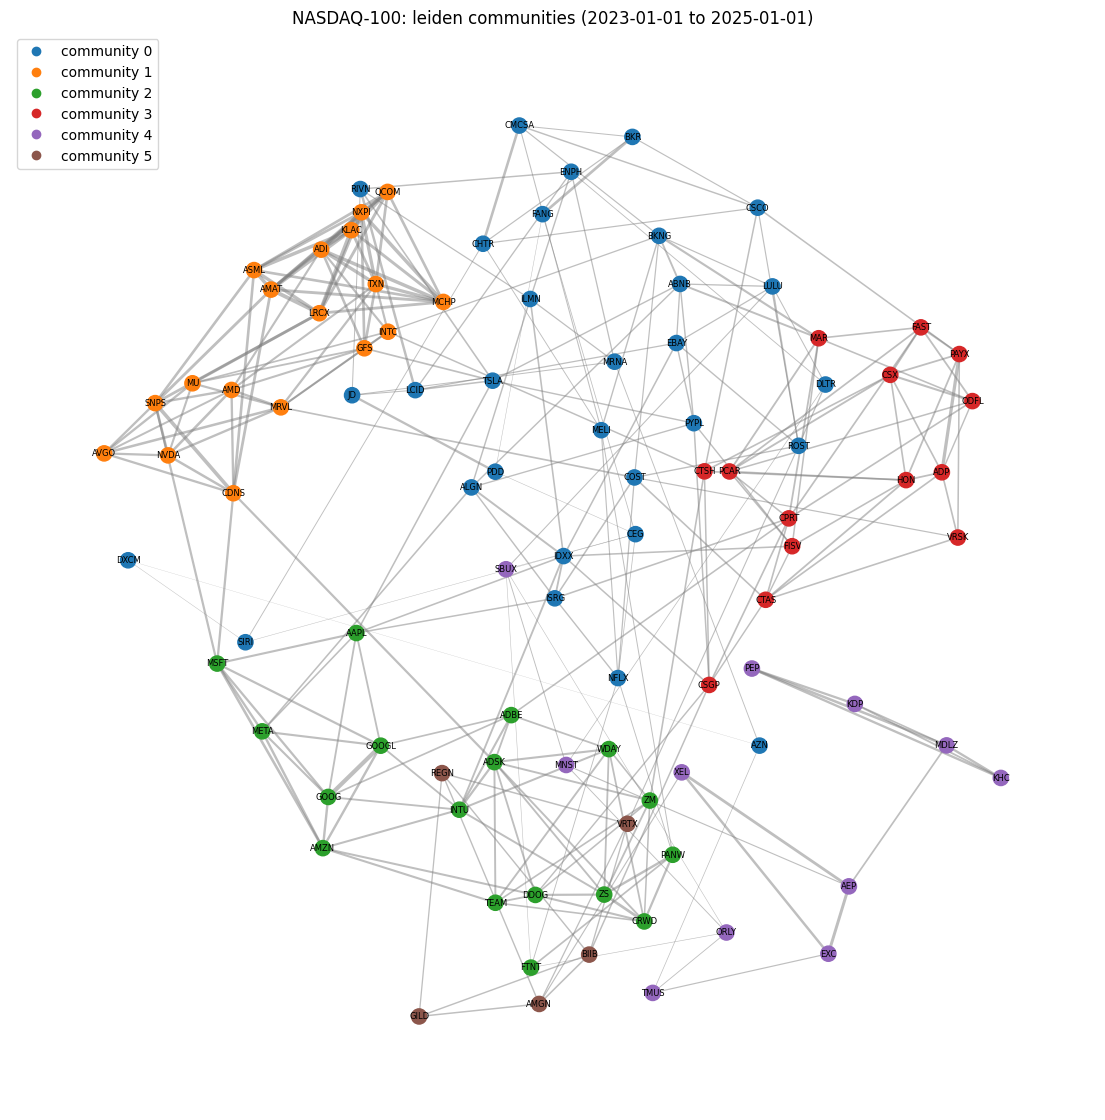

=== leiden communities, 2023-01-01 to 2025-01-01 ===
modularity: 0.659
  community 0: 30 stocks, mainly Consumer Discretionary (12/30)
    ABNB, ALGN, AZN, BKNG, BKR, CEG, CHTR, CMCSA, COST, CSCO, DLTR, DXCM, EBAY, ENPH, FANG, IDXX, ILMN, ISRG, JD, LCID, LULU, MELI, MRNA, NFLX, PDD, PYPL, RIVN, ROST, SIRI, TSLA
  community 1: 18 stocks, mainly Information Technology (18/18)
    ADI, AMAT, AMD, ASML, AVGO, CDNS, GFS, INTC, KLAC, LRCX, MCHP, MRVL, MU, NVDA, NXPI, QCOM, SNPS, TXN
  community 2: 17 stocks, mainly Information Technology (13/17)
    AAPL, ADBE, ADSK, AMZN, CRWD, DDOG, FTNT, GOOG, GOOGL, INTU, META, MSFT, PANW, TEAM, WDAY, ZM, ZS
  community 3: 14 stocks, mainly Industrials (9/14)
    ADP, CPRT, CSGP, CSX, CTAS, CTSH, FAST, FISV, HON, MAR, ODFL, PAYX, PCAR, VRSK
  community 4: 11 stocks, mainly Consumer Staples (5/11)
    AEP, EXC, KDP, KHC, MDLZ, MNST, ORLY, PEP, SBUX, TMUS, XEL
  community 5: 5 stocks, mainly Health Care (5/5)
    AMGN, BIIB, GILD, REGN, VRTX


In [16]:
market.build_graph(GRAPH_TYPE)
print(analyze_graph(market.G))
market.detect_static_communities(n_communities=N_COMMUNITIES, seed=SEED)
market.plot_network_by_sector()
market.plot_network_by_partition("leiden")
market.print_community_summary("leiden")

## 10. Inspect a single window
The communities of the **last** window for the temporal methods, and the network colored by one of them.

=== louvain_temporal communities, window 2024-12-04 to 2024-12-18 ===
modularity: 0.550
  community 2: 22 stocks, mainly Information Technology (9/22)
    ADI, ALGN, CSGP, EBAY, ENPH, GFS, IDXX, ILMN, INTC, JD, LCID, LULU, MCHP, MRNA, NXPI, PDD, QCOM, RIVN, SIRI, TXN, VRTX, WDAY
  community 1: 21 stocks, mainly Information Technology (7/21)
    ABNB, ADSK, AMZN, BIIB, COST, CPRT, CTSH, DXCM, GOOG, GOOGL, HON, INTU, META, MSFT, NFLX, NVDA, ORLY, SBUX, TSLA, ZM, ZS
  community 3: 21 stocks, mainly Industrials (4/21)
    ADP, AEP, AZN, BKNG, BKR, CHTR, CMCSA, CSCO, CSX, CTAS, EXC, FANG, FAST, GILD, MDLZ, MELI, ODFL, PAYX, ROST, TMUS, XEL
  community 0: 17 stocks, mainly Information Technology (13/17)
    AAPL, ADBE, AMAT, ASML, AVGO, CDNS, DLTR, FISV, KLAC, LRCX, MRVL, MU, PCAR, PYPL, REGN, SNPS, VRSK
  community 4: 9 stocks, mainly Information Technology (6/9)
    AMD, CEG, CRWD, DDOG, FTNT, ISRG, MAR, PANW, TEAM
  community 5: 5 stocks, mainly Consumer Staples (4/5)
    AMGN, KDP, KHC, 

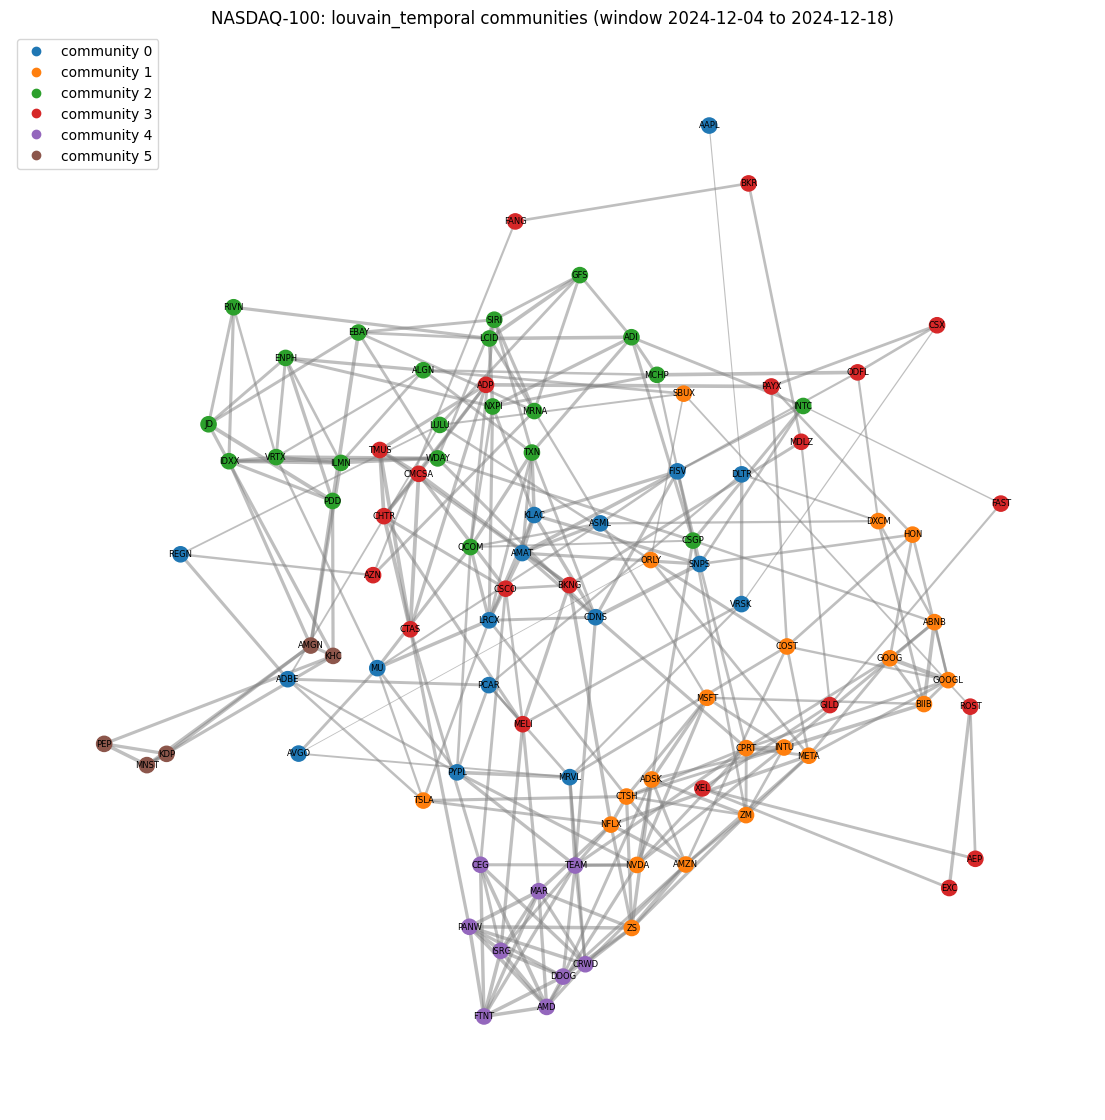

In [17]:
market.print_community_summary("louvain_temporal", window=-1)
market.print_community_summary("leiden_temporal", window=-1)
market.plot_network_by_partition("louvain_temporal", window=-1)